<a href="https://colab.research.google.com/github/aqshal36/Machine-Learning/blob/main/Tugas2_Machine_Learning_Aqshal_Ramadhanu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**<center>$\color{green}{\text{TUGAS 2 : KLASIFIKASI}}$</center>**

> Aqshal Ramadhanu 055540968



---


<p>
Universitas Terbuka adalah sebuah perguruan tinggi terbuka yang memberikan kesempatan bagi putra putri bangsa untuk menimba ilmu dan pengetahuan. UT memiliki mahasiswa dengan latar belakang yang beragam. Mahasiswanya tidak terbatas pada lulusan baru dari sma/smu/smk sederajat. Beberapa diantaranya bahkan telah/sedang bekerja. Kondisi tersebut memberikan kesulitan bagi pihak kampus dalam menerapkan strategi untuk membantu mahasiswa berhasil melewati masa kuliah dan lulus tepat waktu.
</p>

<p>
Sebagai seorang Machine Learning engineer, kamu diminta untuk membuat model yang mampu mendeteksi secara dini tigkat resiko kegagalan seorang mahasiswa. Dengan harapan jika sistem mampu memberikan informasi yang valid, maka bagian wali akademik dapat memberikan konseling yang tepat. Untuk melaksanakan tugasmu ini, kamu diberikan data yang bersumber dari dua periode penerimaan.
</p>


##Task 1
Mulailah memuat semua data yang ada ke sistem.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# 1) Muat data dari kedua sumber
df1 = pd.read_csv("/content/Data Siswa Periode 1.csv")
df2 = pd.read_csv("/content/Data Siswa Periode 2.csv")
print("Ukuran data Periode 1 (baris, kolom):", df1.shape)
print("Ukuran data Periode 2 (baris, kolom):", df2.shape)

# 2) Lihat atribut apa saja yang ada dari kedua data tersebut
perbandingan = pd.DataFrame({"Periode 1": df1.columns, "Periode 2": df2.columns})
perbandingan["Sama?"] = np.where(perbandingan["Periode 1"] == perbandingan["Periode 2"], "Ya", "Tidak")
print(perbandingan)

print("Atribut yang hanya ada di Periode 1:", set(df1.columns) - set(df2.columns))
print("Atribut yang hanya ada di Periode 2:", set(df2.columns) - set(df1.columns))

Ukuran data Periode 1 (baris, kolom): (1827, 21)
Ukuran data Periode 2 (baris, kolom): (1730, 21)
                              Periode 1                            Periode 2  \
0                                    ID                                   ID   
1                     Status Pernikahan                    Status Pernikahan   
2                         Program Studi                        Program Studi   
3                   Kelas Reguler/Malam                    Kelas Siang/Malam   
4                   Pendidikan Terakhir                  Pendidikan Terakhir   
5                             Nilai SMA                            Nilai SMA   
6                           Daerah Asal                          Daerah Asal   
7                        Pendidikan Ibu                       Pendidikan Ibu   
8                       Pendidikan Ayah                      Pendidikan Ayah   
9                         Pekerjaan Ibu                        Pekerjaan Ibu   
10                    

##Task 2
Datanya sudah termuat, fitur nya hampir semuanya sama, tetapi ada yang berbeda sehingga perlu dipetakan

In [2]:
# 1) Identifikasi fitur serupa, lakukan penamaan ulang fitur serupa
pemetaan_nama = {
    "Kelas Siang/Malam": "Kelas Reguler/Malam",
    "Umur saat mendaftar": "Usia saat mendaftar",
}
df2 = df2.rename(columns=pemetaan_nama)

print("Nama kolom kedua data sudah sama:", set(df1.columns) == set(df2.columns))

Nama kolom kedua data sudah sama: True


##Task 3
Butuh penyatuan data, tapi ternyata ada kodefikasi atribut fitur yang berbeda, harus di samakan

In [3]:
# 1) Lakukan penyamaan kodefikasi atribut
kolom_kategorik = df1.select_dtypes(exclude="number").columns
for kol in kolom_kategorik:
    v1 = set(df1[kol].dropna().unique())
    v2 = set(df2[kol].dropna().unique())
    if v1 == v2:
        print(f"{kol:40s} -> sama")
    else:
        print(f"{kol:40s} -> BEDA | hanya di P1: {v1 - v2} | hanya di P2: {v2 - v1}")

# Memperbaiki data di df2 sebelum digabungkan agar sesuai dengan df1
df2["Kelas Reguler/Malam"] = df2["Kelas Reguler/Malam"].replace({"Siang": "Reguler"})
df2["Jenis Kelamin"]       = df2["Jenis Kelamin"].replace({"Laki-laki": "Pria", "Perempuan": "Wanita"})

print("\n--- Setelah disamakan ---")
for kol in ["Kelas Reguler/Malam", "Jenis Kelamin"]:
    print(kol, "| P1:", sorted(df1[kol].dropna().unique()), "| P2:", sorted(df2[kol].dropna().unique()))

# 2) Lakukan penyatuan data
df = pd.concat([df1, df2], ignore_index=True)
print("\nUkuran data gabungan:", df.shape, "(harus", df1.shape[0] + df2.shape[0], "baris )")
display(df.head())

Status Pernikahan                        -> sama
Program Studi                            -> sama
Kelas Reguler/Malam                      -> BEDA | hanya di P1: {'Reguler'} | hanya di P2: {'Siang'}
Pendidikan Terakhir                      -> sama
Daerah Asal                              -> sama
Pendidikan Ibu                           -> sama
Pendidikan Ayah                          -> sama
Pekerjaan Ibu                            -> sama
Pekerjaan Ayah                           -> sama
Pindahan                                 -> sama
Berkebutuhan Khusus                      -> sama
Status pembayaran semester terakhir      -> sama
Jenis Kelamin                            -> BEDA | hanya di P1: {'Wanita', 'Pria'} | hanya di P2: {'Laki-laki', 'Perempuan'}
Beasiswa                                 -> sama
Target                                   -> sama

--- Setelah disamakan ---
Kelas Reguler/Malam | P1: ['Malam', 'Reguler'] | P2: ['Malam', 'Reguler']
Jenis Kelamin | P1: ['Pria', 'Wanita

,ID,Status Pernikahan,Program Studi,Kelas Reguler/Malam,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,Pekerjaan Ayah,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia saat mendaftar,IP Semester 1,IP Semester 2,Target
0,2,Belum Menikah,Teknik Industri,Reguler,SMA/Sederajat,66.55,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Lainnya,Lainnya,53.00,Ya,Tidak,Sudah,Pria,Tidak,21,2.48,2.52,Lulus Tepat Waktu
1,3,Belum Menikah,Jurnalistik,Reguler,SMA/Sederajat,63.50,Pulau Jawa,SMA/Sederajat,Lebih dari S1,Pegawai Swasta,Pegawai Swasta,58.25,Tidak,Tidak,Sudah,Wanita,Ya,19,2.86,2.63,Lulus Tepat Waktu
2,4,Belum Menikah,Pertanian,Reguler,SMA/Sederajat,62.50,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Wiraswasta,Lainnya,60.75,Ya,Tidak,Sudah,Pria,Tidak,18,2.20,2.07,Lulus Tidak Tepat Waktu
3,5,Belum Menikah,Teknik Mesin,Reguler,Perguruan Tinggi,75.00,Pulau Jawa,Lebih dari S1,Lebih dari S1,Pegawai Swasta,Pegawai Swasta,75.00,Tidak,Tidak,Sudah,Wanita,Tidak,20,2.60,2.40,Lulus Tidak Tepat Waktu
4,10,Belum Menikah,Perbankan,Reguler,SMA/Sederajat,65.00,Pulau Jawa,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Negri,Pegawai Negri,64.55,Ya,Tidak,Sudah,Wanita,Tidak,18,2.61,2.72,Lulus Tepat Waktu


##Task 4
Sekarang kita lakukan analisis atribut untuk setiap fitur nya, mulai dengan penanganan missing/null value

In [16]:
# 1)	Identifikasi dan tangani missing/null value
print("Jumlah baris duplikat persis:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran data setelah buang duplikat:", df.shape)
print("ID yang masih ganda:", df["ID"].duplicated().sum())

print("\nJumlah missing value per kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nBaris yang mengandung missing value:")
display(df[df.isnull().any(axis=1)])

for kol in ["Kelas Reguler/Malam", "Daerah Asal"]:
    modus = df[kol].mode()[0]
    print(f"Modus {kol}: {modus}")
    df[kol] = df[kol].fillna(modus)

print("\nTotal missing value setelah penanganan:", df.isnull().sum().sum())

Jumlah baris duplikat persis: 0
Ukuran data setelah buang duplikat: (3535, 21)
ID yang masih ganda: 0

Jumlah missing value per kolom:
Kelas Reguler/Malam    3
Daerah Asal            3
dtype: int64

Baris yang mengandung missing value:


,ID,Status Pernikahan,Program Studi,Kelas Reguler/Malam,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Pekerjaan Ibu,Pekerjaan Ayah,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia saat mendaftar,IP Semester 1,IP Semester 2,Target
658,1317,Belum Menikah,Agronomi,NaN,SMA/Sederajat,54.0,Pulau Jawa,SMA/Sederajat,Lebih dari S1,Pegawai Swasta,Lainnya,55.25,Ya,Tidak,Sudah,Wanita,Ya,22,2.43,2.50,Lulus Tepat Waktu
724,1424,Belum Menikah,Perbankan,Reguler,SMA/Sederajat,75.0,NaN,SMA/Sederajat,Dibawah SMA/Sederajat,Pegawai Swasta,Lainnya,55.00,Ya,Tidak,Sudah,Pria,Ya,33,2.61,2.61,Lulus Tepat Waktu
1118,382,Belum Menikah,Jurnalistik,Reguler,SMA/Sederajat,79.5,NaN,Dibawah SMA/Sederajat,SMA/Sederajat,Pegawai Swasta,Pegawai Swasta,75.65,Ya,Tidak,Sudah,Wanita,Tidak,18,2.80,2.93,Lulus Tepat Waktu
1365,924,Belum Menikah,Penyiaran,Reguler,SMA/Sederajat,58.5,NaN,Dibawah SMA/Sederajat,SMA/Sederajat,Lainnya,Lainnya,60.80,Ya,Tidak,Sudah,Wanita,Tidak,22,2.58,2.90,Lulus Tepat Waktu
1621,1456,Belum Menikah,Manajemen,NaN,SMA/Sederajat,65.0,Luar Jawa,Lebih dari S1,SMA/Sederajat,Pegawai Swasta,Lainnya,62.75,Ya,Tidak,Sudah,Wanita,Ya,19,2.83,2.70,Lulus Tepat Waktu
1761,1719,Belum Menikah,Akuntansi,NaN,SMA/Sederajat,70.0,Pulau Jawa,Lebih dari S1,Lebih dari S1,Lainnya,Lainnya,60.00,Tidak,Tidak,Sudah,Wanita,Tidak,28,2.00,0.00,Gagal


Modus Kelas Reguler/Malam: Reguler
Modus Daerah Asal: Pulau Jawa

Total missing value setelah penanganan: 0


##Task 5
Untuk bisa melihat bentuk dari data, kita perlu menghitung histogram dari setiap fitur. Dari situ kemudian kita bisa lanjutkan dengan penanganan outlier.

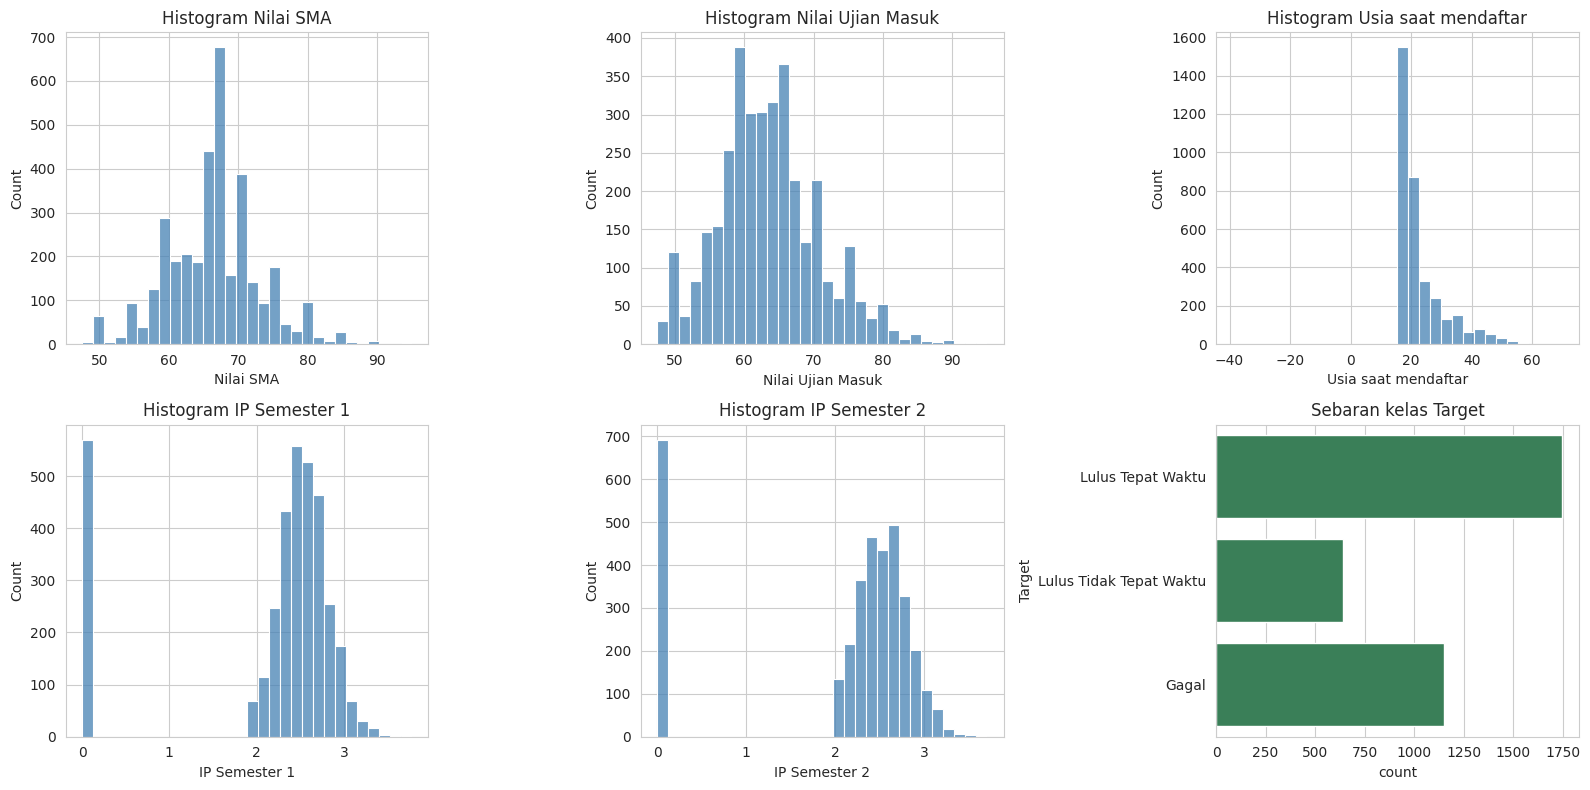

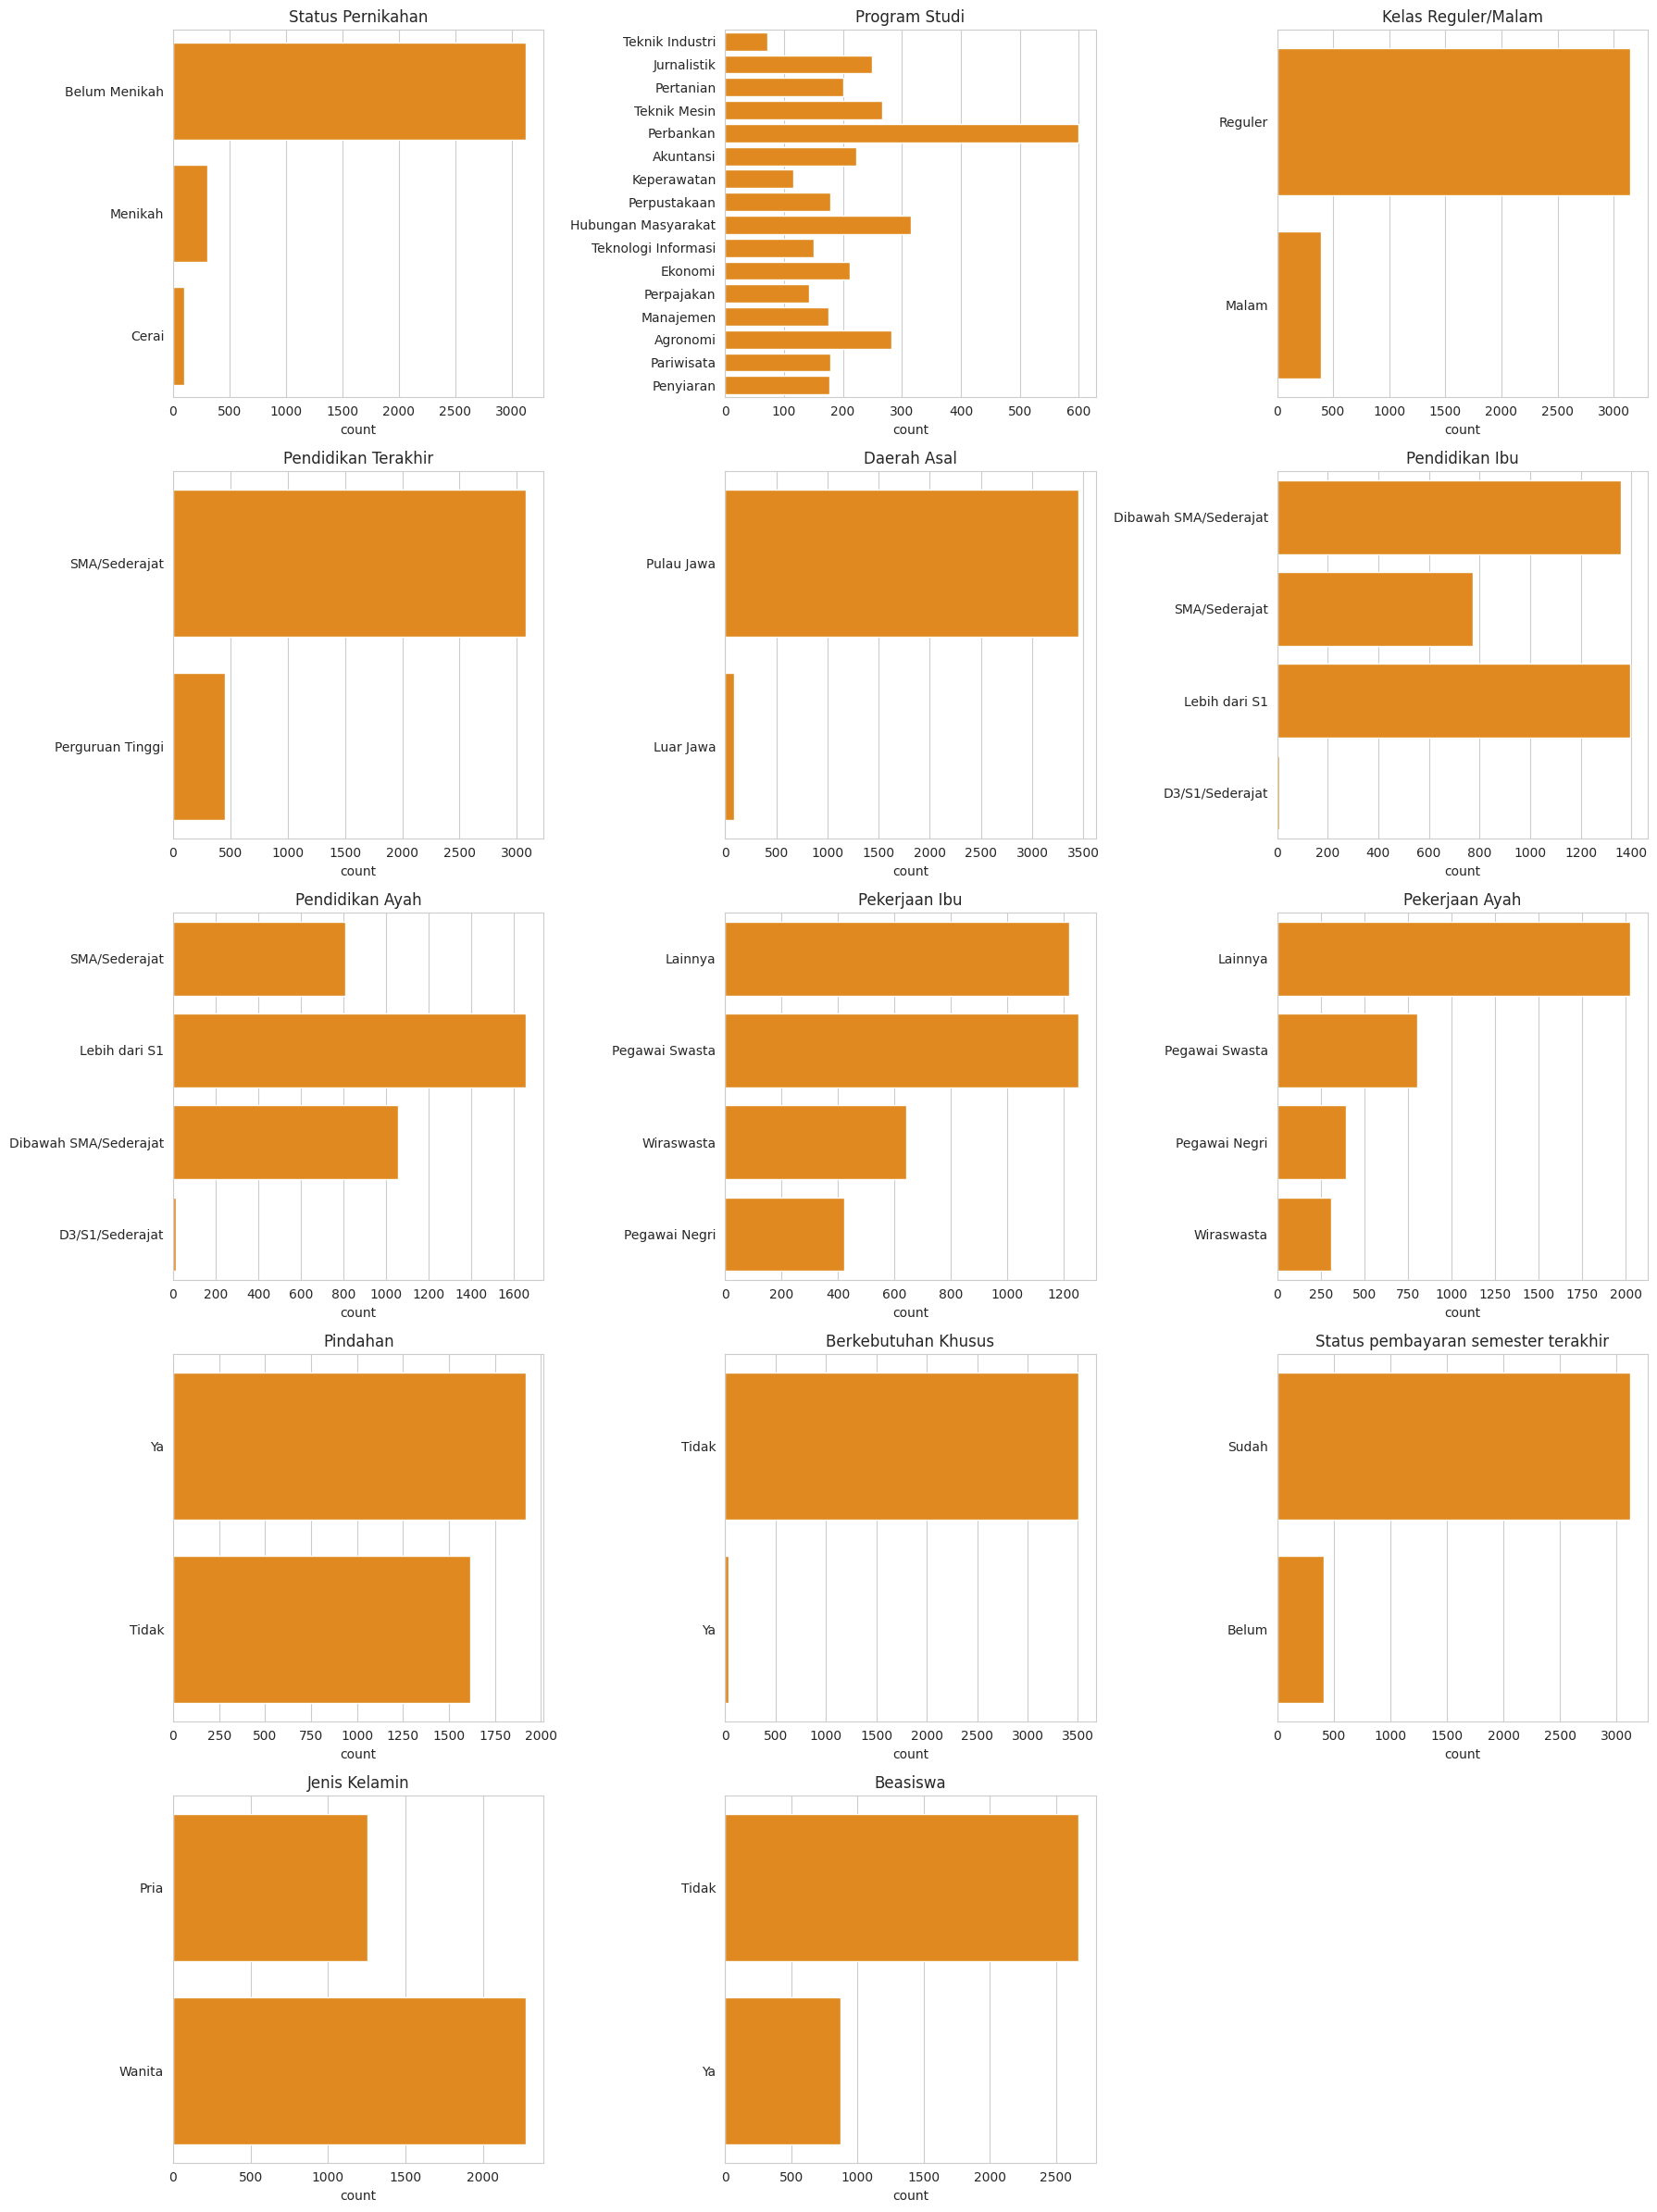

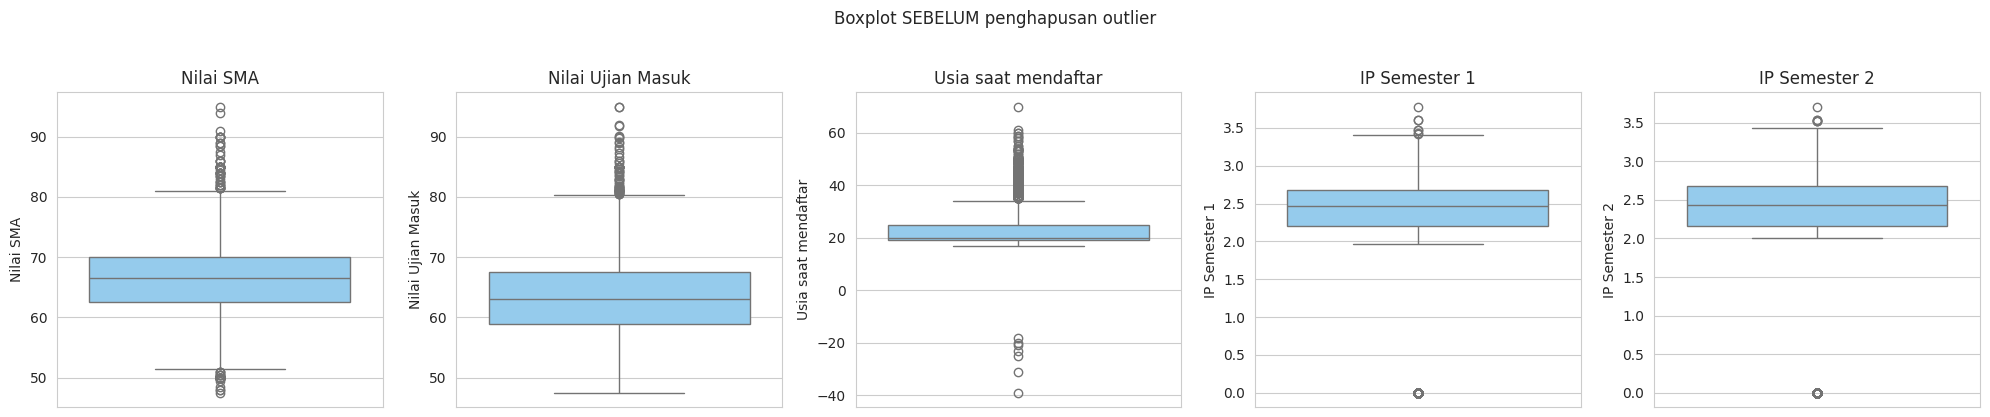

,Fitur,Batas bawah,Batas atas,Jumlah outlier (IQR)
0,Nilai SMA,51.25,81.25,133
1,Nilai Ujian Masuk,46.13,80.32,60
2,Usia saat mendaftar,10.00,34.00,357
3,IP Semester 1,1.48,3.40,577
4,IP Semester 2,1.39,3.45,698


Proporsi Target berdasarkan usia (batas atas IQR usia = 34):


Target,Gagal,Lulus Tepat Waktu,Lulus Tidak Tepat Waktu
Usia > 34,,,
False,0.30,0.51,0.19
True,0.54,0.35,0.11


Proporsi Target berdasarkan IP Semester 2 = 0:


Target,Gagal,Lulus Tepat Waktu,Lulus Tidak Tepat Waktu
IP Smt 2 = 0,,,
False,0.20,0.59,0.21
True,0.83,0.09,0.08


Baris sebelum : 3535
Baris sesudah : 3361
Baris dihapus : 174 (4.9%)


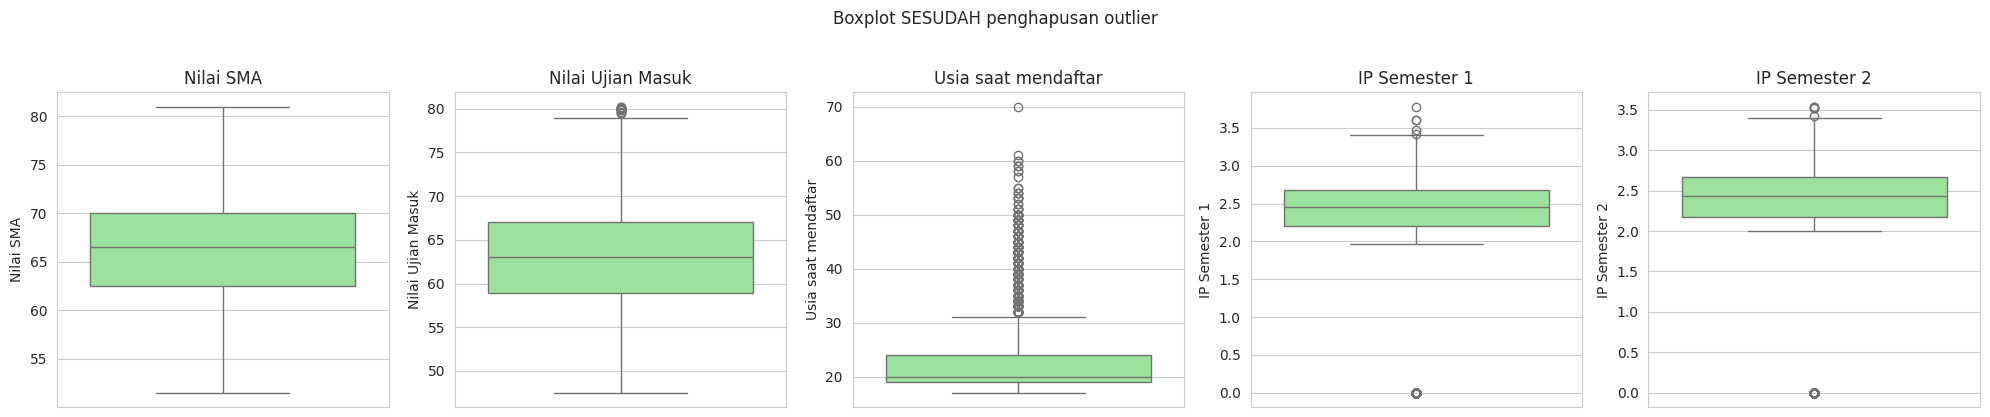

In [21]:
fitur_numerik  = ["Nilai SMA", "Nilai Ujian Masuk", "Usia saat mendaftar", "IP Semester 1", "IP Semester 2"]
fitur_kategorik = [k for k in df.columns if k not in fitur_numerik + ["ID", "Target"]]

# 1)	Hitung histogram setiap fitur, tampilkan dalam bentuk grafik batang
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for ax, kol in zip(axes, fitur_numerik):
    sns.histplot(df[kol], bins=30, ax=ax, color="steelblue")
    ax.set_title(f"Histogram {kol}")
sns.countplot(data=df, y="Target", ax=axes[5], color="seagreen")
axes[5].set_title("Sebaran kelas Target")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 3, figsize=(18, 24))
axes = axes.ravel()
for ax, kol in zip(axes, fitur_kategorik):
    sns.countplot(data=df, y=kol, ax=ax, color="darkorange")
    ax.set_title(kol)
    ax.set_ylabel("")
for ax in axes[len(fitur_kategorik):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


# 2)	Identifikasi outlier dengan boxplot
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, kol in zip(axes, fitur_numerik):
    sns.boxplot(y=df[kol], ax=ax, color="lightskyblue")
    ax.set_title(kol)
plt.suptitle("Boxplot SEBELUM penghapusan outlier", y=1.03)
plt.tight_layout()
plt.show()

def batas_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

ringkas = []
for kol in fitur_numerik:
    bawah, atas = batas_iqr(df[kol])
    n_out = ((df[kol] < bawah) | (df[kol] > atas)).sum()
    ringkas.append([kol, round(bawah, 2), round(atas, 2), n_out])
display(pd.DataFrame(ringkas, columns=["Fitur", "Batas bawah", "Batas atas", "Jumlah outlier (IQR)"]))

print("Proporsi Target berdasarkan usia (batas atas IQR usia = 34):")
display(pd.crosstab(df["Usia saat mendaftar"] > 34, df["Target"], normalize="index").round(2)
        .rename_axis("Usia > 34"))

print("Proporsi Target berdasarkan IP Semester 2 = 0:")
display(pd.crosstab(df["IP Semester 2"] == 0, df["Target"], normalize="index").round(2)
        .rename_axis("IP Smt 2 = 0"))

# 3)	Hapus outlier dari data
mask_valid = df["Usia saat mendaftar"] > 0
for kol in ["Nilai SMA", "Nilai Ujian Masuk"]:
    bawah, atas = batas_iqr(df[kol])
    mask_valid &= df[kol].between(bawah, atas)

df_clean = df[mask_valid].reset_index(drop=True)
print(f"Baris sebelum : {len(df)}")
print(f"Baris sesudah : {len(df_clean)}")
print(f"Baris dihapus : {len(df) - len(df_clean)} ({(len(df) - len(df_clean)) / len(df):.1%})")

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, kol in zip(axes, fitur_numerik):
    sns.boxplot(y=df_clean[kol], ax=ax, color="lightgreen")
    ax.set_title(kol)
plt.suptitle("Boxplot SESUDAH penghapusan outlier", y=1.03)
plt.tight_layout()
plt.show()


##Task 6
Agar nantinya kita bisa mendapatkan fitur yang relevan, sebaiknya kita melihat hubungan setiap fitur dengan kelas target.

Rata-rata fitur numerik per kelas Target:


,Nilai SMA,Nilai Ujian Masuk,Usia saat mendaftar,IP Semester 1,IP Semester 2
Target,,,,,
Gagal,65.53,62.04,25.84,1.48,1.23
Lulus Tidak Tepat Waktu,65.65,62.55,22.07,2.23,2.23
Lulus Tepat Waktu,67.06,64.16,21.56,2.53,2.54


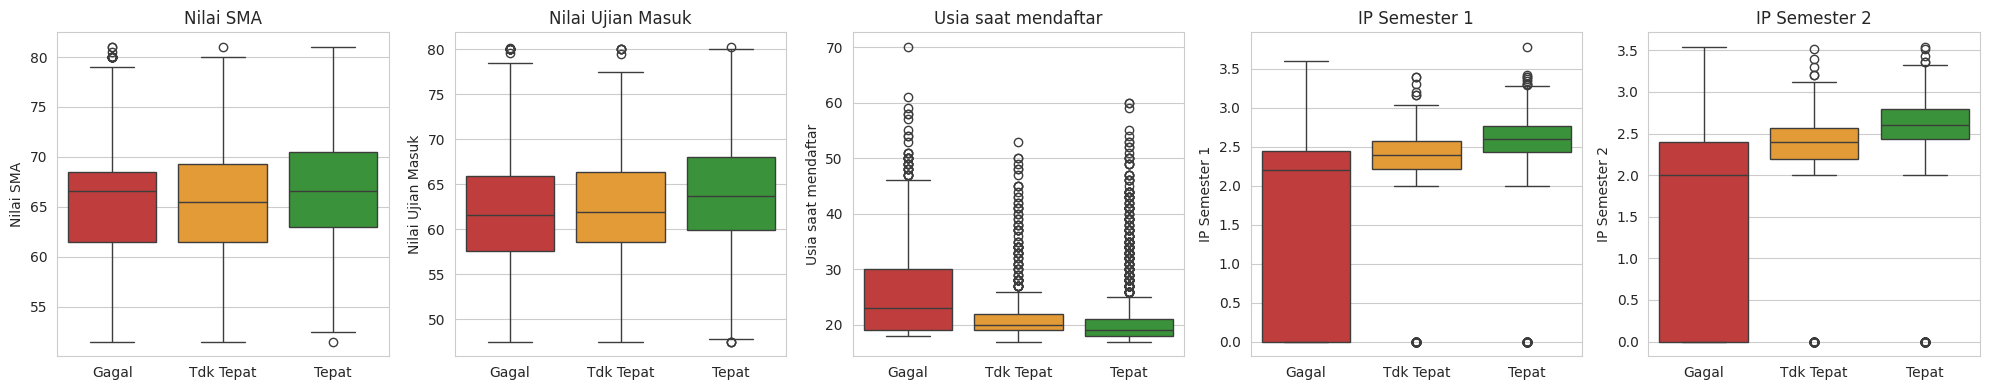

,Fitur numerik,p-value ANOVA
0,Nilai SMA,1.94e-13
1,Nilai Ujian Masuk,2.48e-17
2,Usia saat mendaftar,1.54e-54
3,IP Semester 1,1.40e-200
4,IP Semester 2,3.76e-286


,Fitur kategorik,p-value Chi-square,Cramer's V
0,Status pembayaran semester terakhir,1.12e-135,0.430
1,Beasiswa,2.69e-64,0.295
2,Program Studi,1.81e-73,0.255
3,Jenis Kelamin,4.05e-45,0.247
4,Pendidikan Terakhir,1.08e-09,0.111
5,Pindahan,9.47e-09,0.105
6,Status Pernikahan,3.97e-11,0.090
7,Kelas Reguler/Malam,3.30e-06,0.087
8,Pendidikan Ibu,1.40e-06,0.075
9,Pendidikan Ayah,8.30e-03,0.051


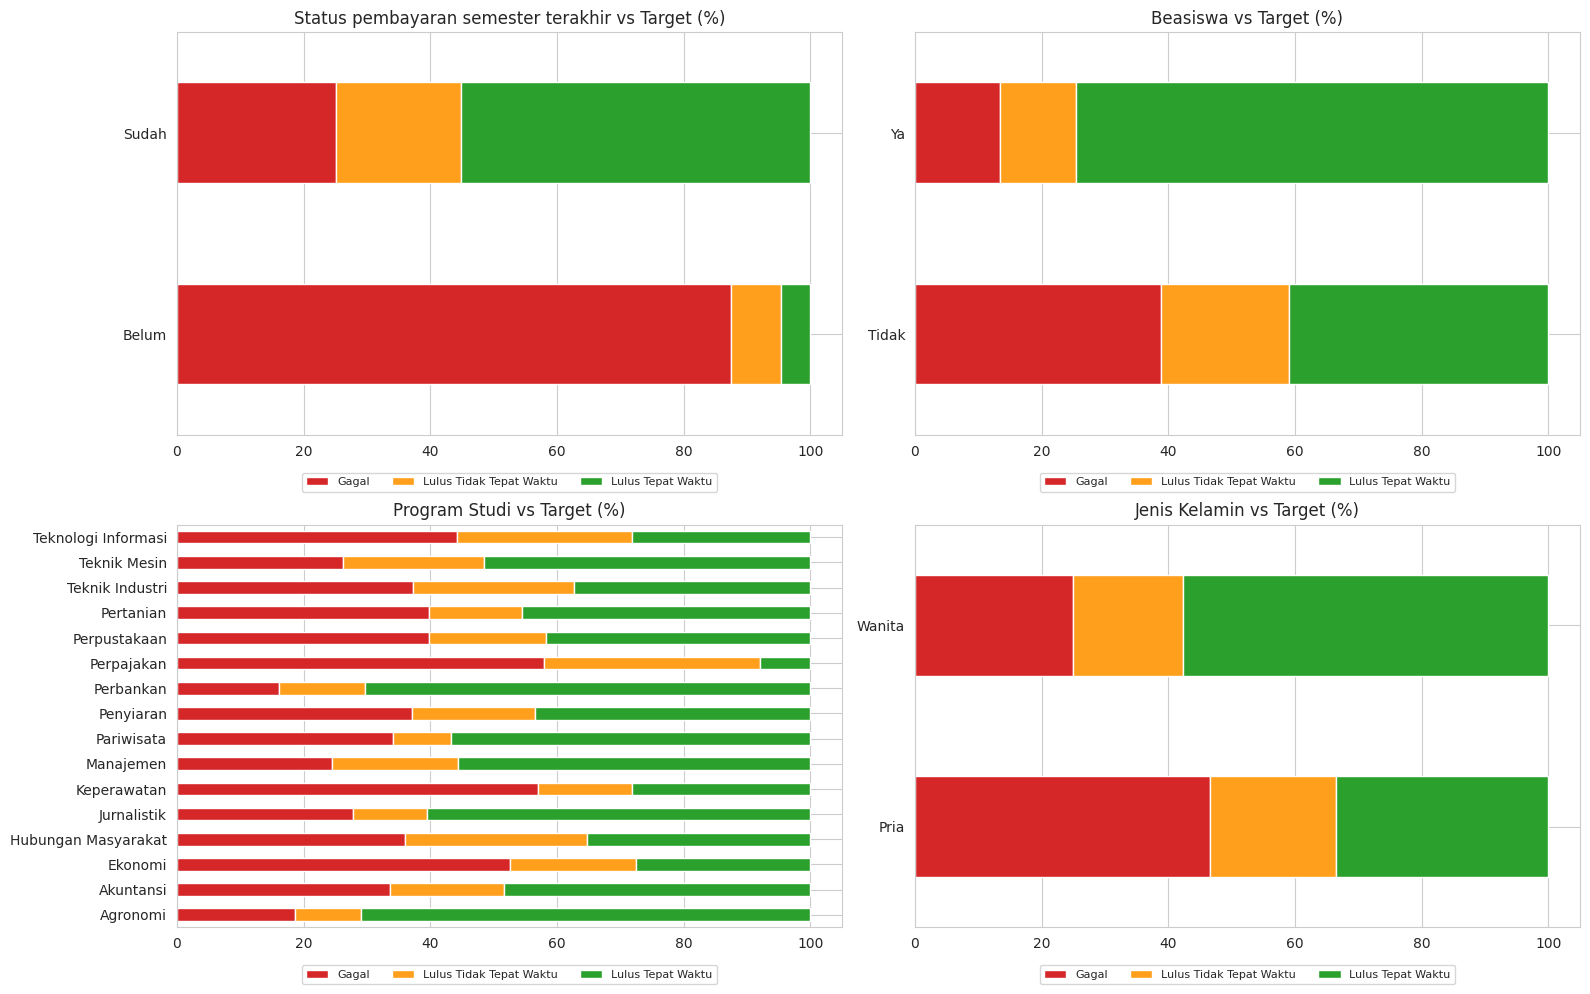

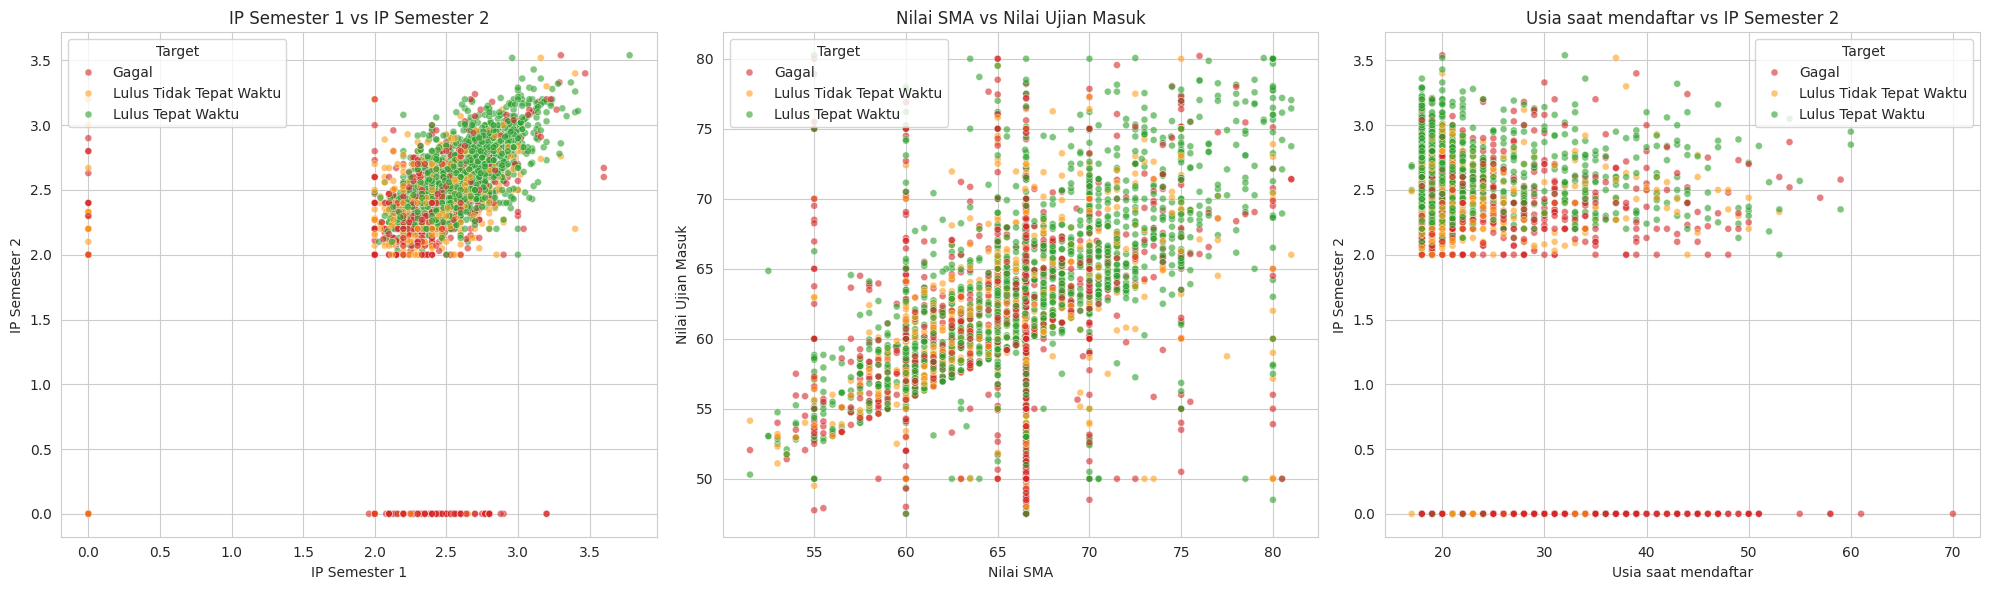

In [24]:
from scipy.stats import f_oneway, chi2_contingency

urutan = ["Gagal", "Lulus Tidak Tepat Waktu", "Lulus Tepat Waktu"]
palet  = {"Gagal": "#d62728", "Lulus Tidak Tepat Waktu": "#ff9f1c", "Lulus Tepat Waktu": "#2ca02c"}

# 1) Lakukan analisis bivariate
print("Rata-rata fitur numerik per kelas Target:")
display(df_clean.groupby("Target")[fitur_numerik].mean().loc[urutan].round(2))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, kol in zip(axes, fitur_numerik):
    sns.boxplot(data=df_clean, x="Target", y=kol, order=urutan, palette=palet, ax=ax)
    ax.set_xlabel("")
    ax.set_xticklabels(["Gagal", "Tdk Tepat", "Tepat"])
    ax.set_title(kol)
plt.tight_layout()
plt.show()

hasil_num = []
for kol in fitur_numerik:
    grup = [g[kol].values for _, g in df_clean.groupby("Target")]
    hasil_num.append([kol, f_oneway(*grup).pvalue])
display(pd.DataFrame(hasil_num, columns=["Fitur numerik", "p-value ANOVA"]).style.format({"p-value ANOVA": "{:.2e}"}))

hasil_kat = []
for kol in fitur_kategorik:
    tabel = pd.crosstab(df_clean[kol], df_clean["Target"])
    chi2, p, _, _ = chi2_contingency(tabel)
    n = tabel.values.sum()
    cramer_v = np.sqrt(chi2 / (n * (min(tabel.shape) - 1)))
    hasil_kat.append([kol, p, cramer_v])
tabel_kat = (pd.DataFrame(hasil_kat, columns=["Fitur kategorik", "p-value Chi-square", "Cramer's V"])
             .sort_values("Cramer's V", ascending=False).reset_index(drop=True))
display(tabel_kat.style.format({"p-value Chi-square": "{:.2e}", "Cramer's V": "{:.3f}"}))

# 2)	Plot kedalam grafik sebaran (scatter)
top4 = tabel_kat["Fitur kategorik"].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, kol in zip(axes.ravel(), top4):
    (pd.crosstab(df_clean[kol], df_clean["Target"], normalize="index")[urutan] * 100) \
        .plot(kind="barh", stacked=True, ax=ax, color=[palet[k] for k in urutan])
    ax.set_title(f"{kol} vs Target (%)")
    ax.set_ylabel("")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
pasangan = [("IP Semester 1", "IP Semester 2"),
            ("Nilai SMA", "Nilai Ujian Masuk"),
            ("Usia saat mendaftar", "IP Semester 2")]
for ax, (xk, yk) in zip(axes, pasangan):
    sns.scatterplot(data=df_clean, x=xk, y=yk, hue="Target", hue_order=urutan,
                    palette=palet, alpha=0.6, s=25, ax=ax)
    ax.set_title(f"{xk} vs {yk}")
plt.tight_layout()
plt.show()


,Jumlah,Persen (%)
Target,,
Lulus Tepat Waktu,1654,49.2
Gagal,1092,32.5
Lulus Tidak Tepat Waktu,615,18.3


Rasio kelas terbesar : terkecil = 2.69 : 1


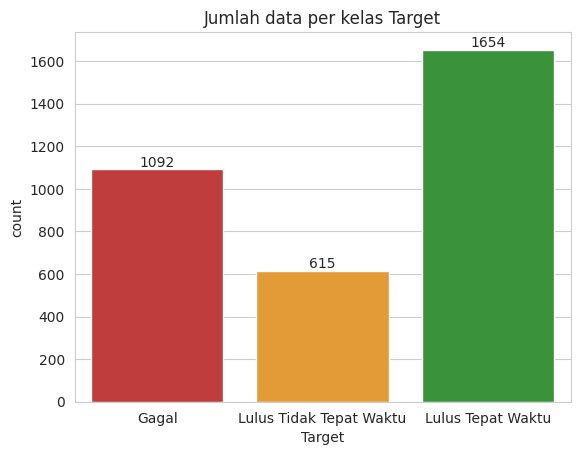

In [25]:
dist = df_clean["Target"].value_counts()
persen = df_clean["Target"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"Jumlah": dist, "Persen (%)": persen}))
print(f"Rasio kelas terbesar : terkecil = {dist.max() / dist.min():.2f} : 1")

ax = sns.countplot(data=df_clean, x="Target", order=urutan, palette=palet)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Jumlah data per kelas Target")
plt.show()

##Task 7
Oke, sepertinya sudah siap, tapi kok jumlah data per-kelas nya tidak seimbang ya, ada beberapa algoritma yang akan terpengaruh dengan kondisi ini, kita akan gunakan algoritma **$\color{orange}{\text{(Nama Algoritma)}}$** untuk menyelesaikan masalah ini, jadi kita **$\color{orange}{\text{(akan/tidak akan)}}$** melakukan proses augmentasi data karena **$\color{orange}{\text{(Alasan melakukan augmentasi/tidak)}}$**

In [26]:
# 1)	Augmentasi data untuk balancing kelas (Optional)
# Keputusan: TIDAK dilakukan augmentasi/oversampling (mis. SMOTE).
# Sebagai gantinya ketidakseimbangan ditangani oleh Random Forest dengan parameter class_weight="balanced"
# pada Task 8, yaitu kelas yang lebih sedikit diberi bobot lebih besar saat training.
bobot = len(df_clean) / (3 * df_clean["Target"].value_counts())
print("Bobot kelas yang akan dipakai model (class_weight='balanced'):")
print(bobot.round(2).to_string())

Bobot kelas yang akan dipakai model (class_weight='balanced'):
Target
Lulus Tepat Waktu          0.68
Gagal                      1.03
Lulus Tidak Tepat Waktu    1.82


In [30]:
data = df_clean.drop(columns="ID").copy()

# Fitur biner -> 0/1
data["Pindahan"]                            = data["Pindahan"].map({"Tidak": 0, "Ya": 1})
data["Berkebutuhan Khusus"]                 = data["Berkebutuhan Khusus"].map({"Tidak": 0, "Ya": 1})
data["Beasiswa"]                            = data["Beasiswa"].map({"Tidak": 0, "Ya": 1})
data["Status pembayaran semester terakhir"] = data["Status pembayaran semester terakhir"].map({"Belum": 0, "Sudah": 1})
data["Jenis Kelamin"]                       = data["Jenis Kelamin"].map({"Wanita": 0, "Pria": 1})
data["Kelas Reguler/Malam"]                 = data["Kelas Reguler/Malam"].map({"Reguler": 0, "Malam": 1})
data["Daerah Asal"]                         = data["Daerah Asal"].map({"Pulau Jawa": 0, "Luar Jawa": 1})
data["Pendidikan Terakhir"]                 = data["Pendidikan Terakhir"].map({"SMA/Sederajat": 0, "Perguruan Tinggi": 1})

# Fitur ordinal (ada urutan tingkat)
urut_pendidikan = {"Dibawah SMA/Sederajat": 0, "SMA/Sederajat": 1, "D3/S1/Sederajat": 2, "Lebih dari S1": 3}
data["Pendidikan Ibu"]  = data["Pendidikan Ibu"].map(urut_pendidikan)
data["Pendidikan Ayah"] = data["Pendidikan Ayah"].map(urut_pendidikan)

# Fitur nominal -> one-hot
data = pd.get_dummies(data, columns=["Status Pernikahan", "Program Studi", "Pekerjaan Ibu", "Pekerjaan Ayah"], dtype=int)

# Pisahkan fitur (X) dan target (y)
X = data.drop(columns="Target")
y = data["Target"]
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
print("Masih ada nilai kosong setelah encoding?", X.isnull().any().any())
display(X.head())

Bentuk X: (3361, 42) | Bentuk y: (3361,)
Masih ada nilai kosong setelah encoding? False


,Kelas Reguler/Malam,Pendidikan Terakhir,Nilai SMA,Daerah Asal,Pendidikan Ibu,Pendidikan Ayah,Nilai Ujian Masuk,Pindahan,Berkebutuhan Khusus,Status pembayaran semester terakhir,Jenis Kelamin,Beasiswa,Usia saat mendaftar,IP Semester 1,IP Semester 2,Status Pernikahan_Belum Menikah,Status Pernikahan_Cerai,Status Pernikahan_Menikah,Program Studi_Agronomi,Program Studi_Akuntansi,Program Studi_Ekonomi,Program Studi_Hubungan Masyarakat,Program Studi_Jurnalistik,Program Studi_Keperawatan,Program Studi_Manajemen,Program Studi_Pariwisata,Program Studi_Penyiaran,Program Studi_Perbankan,Program Studi_Perpajakan,Program Studi_Perpustakaan,Program Studi_Pertanian,Program Studi_Teknik Industri,Program Studi_Teknik Mesin,Program Studi_Teknologi Informasi,Pekerjaan Ibu_Lainnya,Pekerjaan Ibu_Pegawai Negri,Pekerjaan Ibu_Pegawai Swasta,Pekerjaan Ibu_Wiraswasta,Pekerjaan Ayah_Lainnya,Pekerjaan Ayah_Pegawai Negri,Pekerjaan Ayah_Pegawai Swasta,Pekerjaan Ayah_Wiraswasta
0,0,0,66.55,0,0,1,53.00,1,0,1,1,0,21,2.48,2.52,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0
1,0,0,63.50,0,1,3,58.25,0,0,1,0,1,19,2.86,2.63,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
2,0,0,62.50,0,0,1,60.75,1,0,1,1,0,18,2.20,2.07,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0
3,0,1,75.00,0,3,3,75.00,0,0,1,0,0,20,2.60,2.40,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
4,0,0,65.00,0,0,1,64.55,1,0,1,0,0,18,2.61,2.72,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0


Selanjutnya datanya perlu kita bagi dengan ratio **$\color{orange}{\text{(.?.)}}$** : **$\color{orange}{\text{(.?.)}}$**
Dimana **$\color{orange}{\text{(.?.)}}$** adalah data training
Dan **$\color{orange}{\text{(.?.)}}$** adalah data testing


In [31]:
# 1)	Lakukan pembagian data training dan testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Data training:", X_train.shape, "| Data testing:", X_test.shape)
print("\nProporsi kelas (%) pada data training:")
print(y_train.value_counts(normalize=True).mul(100).round(1).to_string())
print("\nProporsi kelas (%) pada data testing:")
print(y_test.value_counts(normalize=True).mul(100).round(1).to_string())

Data training: (2688, 42) | Data testing: (673, 42)

Proporsi kelas (%) pada data training:
Target
Lulus Tepat Waktu          49.2
Gagal                      32.5
Lulus Tidak Tepat Waktu    18.3

Proporsi kelas (%) pada data testing:
Target
Lulus Tepat Waktu          49.2
Gagal                      32.5
Lulus Tidak Tepat Waktu    18.3


##Task 8
Sekarang kita mulai training nya

In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1) Lakukan proses training dengan algoritma yang telah dipilih
model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",   # penanganan ketidakseimbangan kelas
    min_samples_leaf=3,        # daun minimal 3 data -> mengurangi overfitting
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)
print("Training selesai. Jumlah pohon:", model.n_estimators)

# 2) Lakukan evaluasi model dengan K-fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_validate(model, X_train, y_train, cv=skf, scoring=["accuracy", "f1_macro"])

hasil_cv = pd.DataFrame({"Fold": range(1, 6),
                         "Akurasi": cv["test_accuracy"],
                         "F1-macro": cv["test_f1_macro"]})
display(hasil_cv.round(4))
print(f"Rata-rata akurasi  : {cv['test_accuracy'].mean():.4f} (+/- {cv['test_accuracy'].std():.4f})")
print(f"Rata-rata F1-macro : {cv['test_f1_macro'].mean():.4f} (+/- {cv['test_f1_macro'].std():.4f})")

Training selesai. Jumlah pohon: 200


,Fold,Akurasi,F1-macro
0,1,0.7305,0.6505
1,2,0.7212,0.6655
2,3,0.6840,0.6047
3,4,0.7002,0.6332
4,5,0.7207,0.6532


Rata-rata akurasi  : 0.7113 (+/- 0.0169)
Rata-rata F1-macro : 0.6414 (+/- 0.0211)


#Task 9
Training sudah selesai dan model sudah diketahui, kita uji hasilnya dengan data testing untuk melihat kemungkinan overfitting dan underfitting, sekaligus menghitung kualitas model dengan matrik pengukuran

In [42]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1) Evaluasi dengan data testing
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test  = accuracy_score(y_test, y_pred_test)
print(f"Akurasi training : {acc_train:.4f}")
print(f"Akurasi testing  : {acc_test:.4f}")
print(f"Selisih          : {acc_train - acc_test:.4f}")
print(f"Rata-rata akurasi CV (Task 8): {cv['test_accuracy'].mean():.4f}")

if acc_train > acc_test + 0.1:
    print("-> Model kemungkinan overfitting")
elif acc_train < 0.7 and acc_test < 0.7:
    print("-> Model kemungkinan underfitting")
else:
    print("-> Model dalam batas wajar (tidak overfitting maupun underfitting)")

Akurasi training : 0.9096
Akurasi testing  : 0.7117
Selisih          : 0.1979
Rata-rata akurasi CV (Task 8): 0.7113
-> Model kemungkinan overfitting


In [43]:
hasil_eksp = []
for leaf in [1, 3, 5, 10, 20]:
    m = RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=leaf,
                               random_state=42, n_jobs=-1)
    sk = cross_validate(m, X_train, y_train, cv=skf, scoring=["accuracy", "f1_macro"], return_train_score=True)
    hasil_eksp.append([leaf, sk["train_accuracy"].mean(), sk["test_accuracy"].mean(), sk["test_f1_macro"].mean()])

tabel_eksp = pd.DataFrame(hasil_eksp, columns=["min_samples_leaf", "Akurasi train (CV)", "Akurasi validasi (CV)", "F1-macro validasi (CV)"])
tabel_eksp["Selisih"] = tabel_eksp["Akurasi train (CV)"] - tabel_eksp["Akurasi validasi (CV)"]
display(tabel_eksp.round(3))

,min_samples_leaf,Akurasi train (CV),Akurasi validasi (CV),F1-macro validasi (CV),Selisih
0,1,1.000,0.721,0.599,0.279
1,3,0.913,0.711,0.641,0.201
2,5,0.844,0.697,0.637,0.147
3,10,0.779,0.685,0.636,0.095
4,20,0.733,0.680,0.637,0.053


Classification report (data testing):

                         precision    recall  f1-score   support

                  Gagal      0.783     0.676     0.725       219
Lulus Tidak Tepat Waktu      0.405     0.382     0.393       123
      Lulus Tepat Waktu      0.772     0.858     0.813       331

               accuracy                          0.712       673
              macro avg      0.653     0.639     0.644       673
           weighted avg      0.708     0.712     0.708       673

F1-macro    : 0.6438
F1-weighted : 0.7076


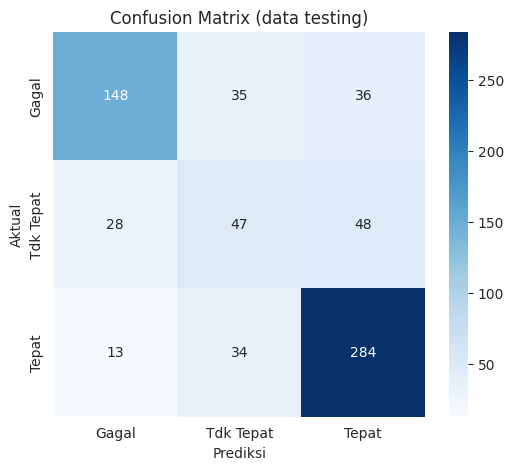

In [44]:
# 2) Hitung dengan matrik pengukuran
print("Classification report (data testing):\n")
print(classification_report(y_test, y_pred_test, labels=urutan, digits=3))
print(f"F1-macro    : {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"F1-weighted : {f1_score(y_test, y_pred_test, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_test, labels=urutan)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Gagal", "Tdk Tepat", "Tepat"], yticklabels=["Gagal", "Tdk Tepat", "Tepat"])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix (data testing)")
plt.show()

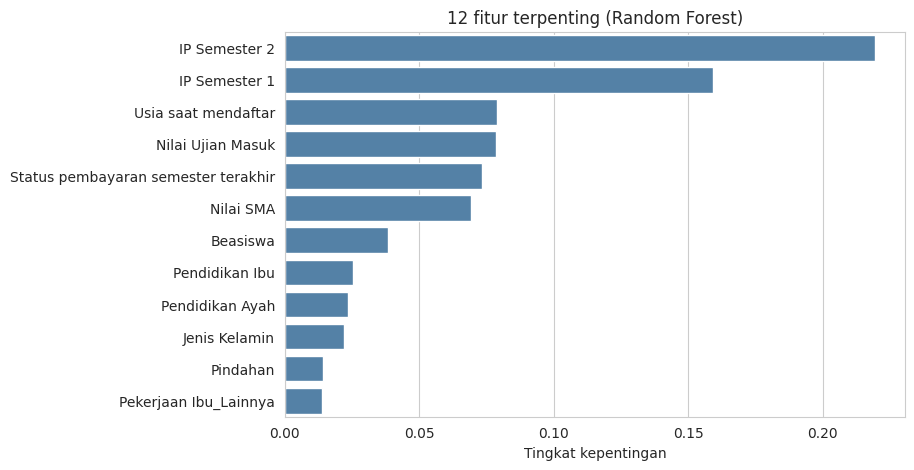

In [45]:
# Tambahan: fitur apa yang paling berpengaruh bagi model?
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("12 fitur terpenting (Random Forest)")
plt.ylabel("")
plt.xlabel("Tingkat kepentingan")
plt.show()

##Task 10
Berdasarkan hasil evaluasi, kita bisa menyimpulkan bahwa

**1. Kualitas model secara keseluruhan.** Random Forest (200 pohon, `class_weight="balanced"`, `min_samples_leaf=3`) menghasilkan akurasi **71.2%** pada data testing dan F1-macro **0.644**. Hasil cross-validation 5-fold pada data training (akurasi 71.1% ± 1.7%) hampir sama dengan hasil data testing, sehingga estimasi performa ini stabil dan bisa dipercaya. Angka ini jauh di atas tebakan kelas mayoritas (49.2%), tetapi belum tergolong sangat tinggi.

**2. Performa per kelas tidak merata.**
- *Lulus Tepat Waktu*: terbaik (F1 = 0.81, recall 0.86; 284 dari 331 tertebak benar).
- *Gagal*: cukup baik (F1 = 0.73, precision 0.78, recall 0.68; 148 dari 219 terdeteksi).
- *Lulus Tidak Tepat Waktu*: lemah (F1 = 0.39; hanya 47 dari 123 tertebak benar, 48 di antaranya salah diprediksi "Tepat Waktu"). Kelas ini berada "di tengah": rata-rata IP-nya (2.23) berada di antara Gagal (1.2 sampai 1.5) dan Tepat Waktu (2.5), jadi ciri-cirinya tumpang tindih dengan dua kelas lain. Ia juga kelas paling sedikit (18%).

**3. Overfitting.** Akurasi training 0.910 vs testing 0.712 (selisih 0.198), sehingga menurut aturan selisih > 0.1 model **terindikasi overfitting**. Namun eksperimen tambahan menunjukkan ini bukan kegagalan generalisasi yang bisa diperbaiki sederhana: ketika model dibatasi lebih kuat (`min_samples_leaf` makin besar), selisih train-validasi mengecil (0.28 menjadi 0.05) tetapi akurasi validasi justru turun (0.721 menjadi 0.680) dan F1-macro tidak membaik. Nilai `min_samples_leaf=3` dipilih karena F1-macro-nya jauh lebih baik daripada pengaturan awal (0.641 vs 0.599). Dengan kata lain, model menghafal data training (hal yang wajar pada Random Forest), tetapi performa pada data baru tetap konsisten sekitar 71%. Ini juga **bukan underfitting**, sebab akurasi training sangat tinggi. Batas performa lebih disebabkan oleh informasi pada data, terutama sulitnya membedakan kelas "Tidak Tepat Waktu".

**4. Fitur yang paling berpengaruh.** `IP Semester 2` dan `IP Semester 1` adalah yang terpenting, diikuti `Usia saat mendaftar`, `Nilai Ujian Masuk`, `Status pembayaran semester terakhir`, `Nilai SMA`, dan `Beasiswa`. Ini sejalan dengan analisis bivariate di Task 6: IP = 0 hampir selalu berarti Gagal, mahasiswa yang belum membayar 88% Gagal, dan penerima beasiswa jauh lebih sering lulus tepat waktu. Catatan: *feature importance* Random Forest cenderung melebihkan fitur numerik kontinu, jadi `Nilai SMA` dan `Nilai Ujian Masuk` kemungkinan tampak lebih penting daripada pengaruh sebenarnya (selisih rata-ratanya antar kelas hanya sekitar 1 sampai 2 poin).

**5. Implikasi untuk wali akademik.** Tujuan model adalah deteksi dini mahasiswa berisiko. Model menangkap sekitar 68% mahasiswa yang akhirnya Gagal, tetapi masih ada 36 dari 219 mahasiswa Gagal yang diprediksi "Lulus Tepat Waktu" (tidak terdeteksi). Karena itu prediksi sebaiknya dipakai sebagai **penyaring awal untuk memprioritaskan konseling**, bukan satu-satunya dasar keputusan. Perlu diingat pula bahwa model memakai IP semester 1 dan 2, sehingga "deteksi dini" baru bisa dilakukan setelah semester kedua selesai.

**6. Saran pengembangan.** (a) Tambahkan fitur perilaku seperti kehadiran, jumlah SKS yang diambil, atau aktivitas belajar daring, agar kelas "Tidak Tepat Waktu" lebih mudah dibedakan. (b) Coba algoritma lain (misalnya Gradient Boosting) disertai tuning hyperparameter. (c) Sesuaikan ambang keputusan agar *recall* kelas Gagal naik, bila menurut pihak kampus lebih penting tidak melewatkan mahasiswa berisiko daripada menghindari peringatan yang berlebih.
